In [1]:
import numpy as np
import scipy as sc
import matplotlib.pyplot as plt

In [28]:
# part b
Q = np.array([[-2, 2, 0, 0], [1, -3, 2, 0], [0, 2, -4, 2], [0, 0, 3, -3]])
eigs = sc.linalg.eig(Q)[0].real
eigs_sorted = np.sort(eigs)[::-1]
print(eigs_sorted)
print(np.sum(eigs))

[-2.38849591e-16 -1.51071143e+00 -3.71083145e+00 -6.77845712e+00]
-12.000000000000004


In [ ]:
# part c
x0 = np.array([1,0,0,0])
pi = np.array([3/19, 6/19, 6/19, 4/19])
t_vals = np.linspace(0, 5, 200)
x = lambda t: x0 @ sc.linalg.expm(t*Q)
x_eval = np.array([x(t) for t in t_vals])

tv = lambda t: 0.5 * np.sum(np.abs(x(t) - pi))
tv_eval = np.array([tv(t) for t in t_vals])

lambd_2 = eigs_sorted[1]
print(f' ln(100)/|lambda_2| = {np.log(100)/np.abs(lambd_2):.6f}')

t_001 = np.interp(0.01, tv_eval[::-1], t_vals[::-1])
print(f'Interpolated time when TV(t) = 0.01 {t_001:.6f}')



 ln(100)/|lambda_2| = 3.048345
Interpolated time when TV(t) = 0.01 2.898098


Text(0.5, 1.0, '$x_i(t)$ and $TV(t)$ for $i=0,1,2,3$')

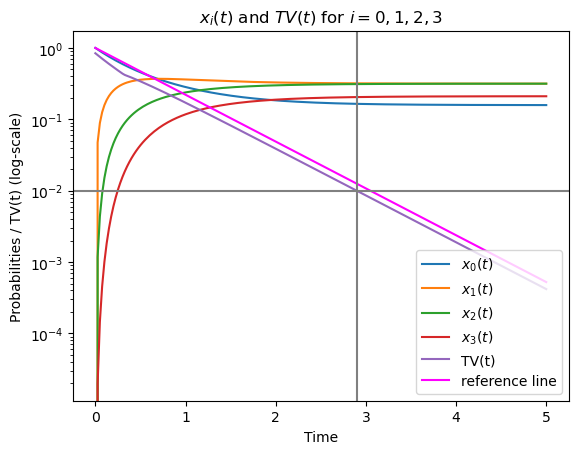

In [61]:
plt.semilogy(t_vals, x_eval[:, 0], label='$x_0(t)$')
plt.semilogy(t_vals, x_eval[:, 1], label='$x_1(t)$')
plt.semilogy(t_vals, x_eval[:, 2], label='$x_2(t)$')
plt.semilogy(t_vals, x_eval[:, 3], label='$x_3(t)$')
plt.semilogy(t_vals, tv_eval, label='TV(t)')
plt.semilogy(t_vals, np.exp(lambd_2 * t_vals), color='magenta', label='reference line')
plt.axhline(0.01, color='gray')
plt.axvline(t_001, color='gray')
#plt.axhline(4/19, color='magenta')
plt.legend(loc='lower right')
plt.xlabel('Time')
plt.ylabel('Probabilities / TV(t) (log-scale)')
plt.title('$x_i(t)$ and $TV(t)$ for $i=0,1,2,3$')


